# Tema 10 — Mapas de calor con seaborn
**Curso:** ME101 · Programación Estadística y Visualización de Datos  
**Estudiante:** Apellido Nombre  
**Fecha:** 04/11/2026

Se reconstruye el mismo dataset y la misma matriz de correlación del Tema 9.

## Paso 5 — Reconstrucción del dataset y la matriz de correlación

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Dataset del Tema 9 (10 estudiantes, 4 variables)
datos = {
    "horas_estudio": [2, 4, 5, 3, 6, 8, 7, 1, 9, 5],
    "horas_redes":   [6, 5, 3, 6, 3, 1, 2, 7, 1, 4],
    "asistencia":    [70, 65, 85, 60, 80, 90, 75, 55, 95, 88],
    "nota_final":    [10, 12, 13, 11, 15, 16, 15, 8, 17, 12],
}
df = pd.DataFrame(datos)
corr = df.corr(method="pearson")
print(corr.round(4))

               horas_estudio  horas_redes  asistencia  nota_final
horas_estudio         1.0000      -0.9808      0.8417      0.9828
horas_redes          -0.9808       1.0000     -0.8674     -0.9661
asistencia            0.8417      -0.8674      1.0000      0.8019
nota_final            0.9828      -0.9661      0.8019      1.0000


## Paso 6 — Heatmap anotado con `sns.heatmap()`

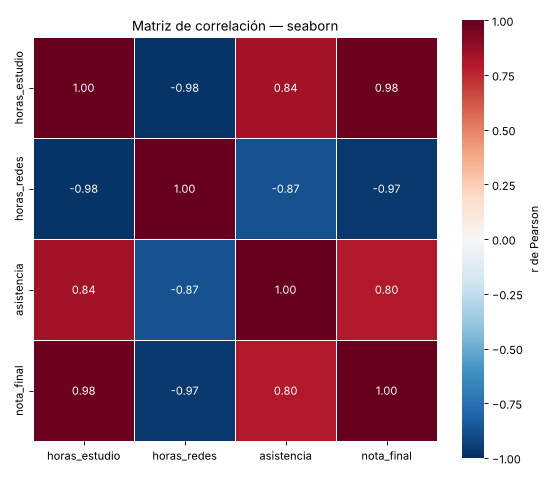

In [2]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "r de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación — seaborn")
plt.tight_layout()
plt.savefig("heatmap_seaborn.png", dpi=150)
plt.show()

## Paso 7 — Máscara con `np.triu()` para ocultar el triángulo superior

Celdas visibles: 6 de 16


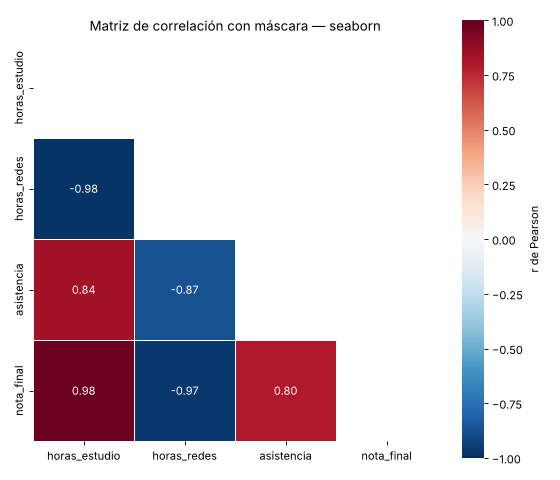

In [3]:
mascara = np.triu(np.ones_like(corr, dtype=bool))
print("Celdas visibles:", int((~mascara).sum()), "de", mascara.size)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "r de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación con máscara — seaborn")
plt.tight_layout()
plt.savefig("heatmap_seaborn_mascara.png", dpi=150)
plt.show()

**Observación:** con 4 variables hay 16 celdas; `np.triu()` oculta la diagonal y el triángulo superior (10 celdas), así que quedan 6 visibles, que son exactamente los 6 pares únicos de variables.